## Experiment: critical regions for normal tests.

Left cutoff: -1.6449
Right cutoff: 1.6449
Two-sided cutoffs: -1.9600, 1.9600
Reject left-tailed: False
Reject right-tailed: True
Reject two-sided: True


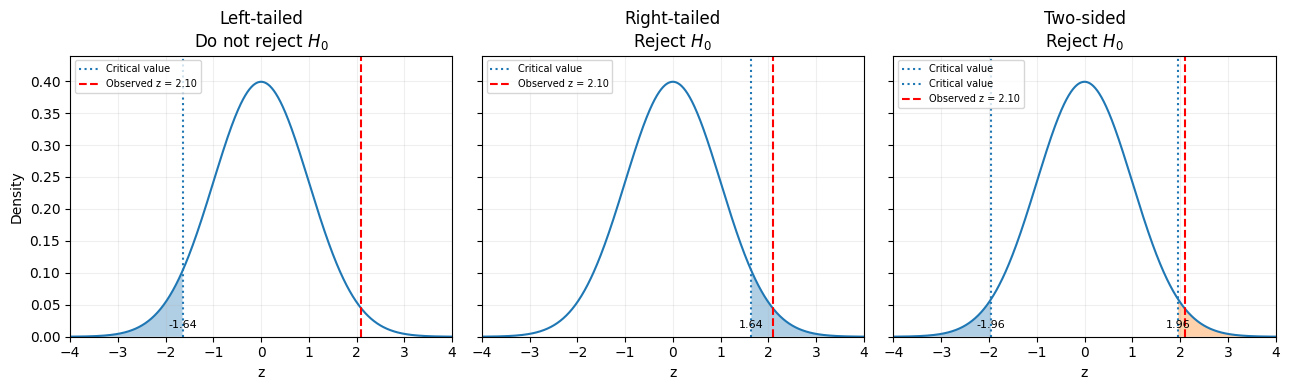

In [3]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

alpha = 0.05
z_obs = 2.10

left = norm.ppf(alpha)
right = norm.isf(alpha)
two_lower = norm.ppf(alpha / 2)
two_upper = norm.isf(alpha / 2)

print(f"Left cutoff: {left:.4f}")
print(f"Right cutoff: {right:.4f}")
print(f"Two-sided cutoffs: {two_lower:.4f}, {two_upper:.4f}")

print("Reject left-tailed:", z_obs <= left)
print("Reject right-tailed:", z_obs >= right)
print("Reject two-sided:", abs(z_obs) >= two_upper)

x = np.linspace(-4, 4, 1000)
y = norm.pdf(x)

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)

tests = [
    ("Left-tailed", [left], z_obs <= left),
    ("Right-tailed", [right], z_obs >= right),
    (
        "Two-sided",
        [two_lower, two_upper],
        abs(z_obs) >= two_upper
    )
]

for ax, (title, cutoffs, reject) in zip(axes, tests):
    ax.plot(x, y)

    # Shade the rejection region(s).
    if title == "Left-tailed":
        tail_x = np.linspace(-4, left, 400)
        ax.fill_between(tail_x, norm.pdf(tail_x), alpha=0.35)

    elif title == "Right-tailed":
        tail_x = np.linspace(right, 4, 400)
        ax.fill_between(tail_x, norm.pdf(tail_x), alpha=0.35)

    else:
        for start, end in [(-4, two_lower), (two_upper, 4)]:
            tail_x = np.linspace(start, end, 400)
            ax.fill_between(tail_x, norm.pdf(tail_x), alpha=0.35)

    # Show the critical value(s).
    for cutoff in cutoffs:
        ax.axvline(
            cutoff,
            linestyle=":",
            linewidth=1.5,
            label="Critical value"
        )
        ax.text(
            cutoff, 0.01, f"{cutoff:.2f}",
            ha="center", va="bottom", fontsize=8
        )

    # Show the observed test statistic.
    ax.axvline(
        z_obs,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label=f"Observed z = {z_obs:.2f}"
    )

    decision = "Reject" if reject else "Do not reject"

    ax.set_title(f"{title}\n{decision} $H_0$")
    ax.set_xlabel("z")
    ax.set_xlim(-4, 4)
    ax.set_ylim(0, 0.44)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=7, loc="upper left")

axes[0].set_ylabel("Density")

fig.tight_layout()
fig.savefig(
    "../../images/critical_regions.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()

# Experiment: change alpha to 0.01 and compare the regions.

## Experiment: p-values and tail areas.

Left-tailed: p=0.98214 - Fail to reject H0
Right-tailed: p=0.01786 - Reject H0
Two-sided: p=0.03573 - Reject H0


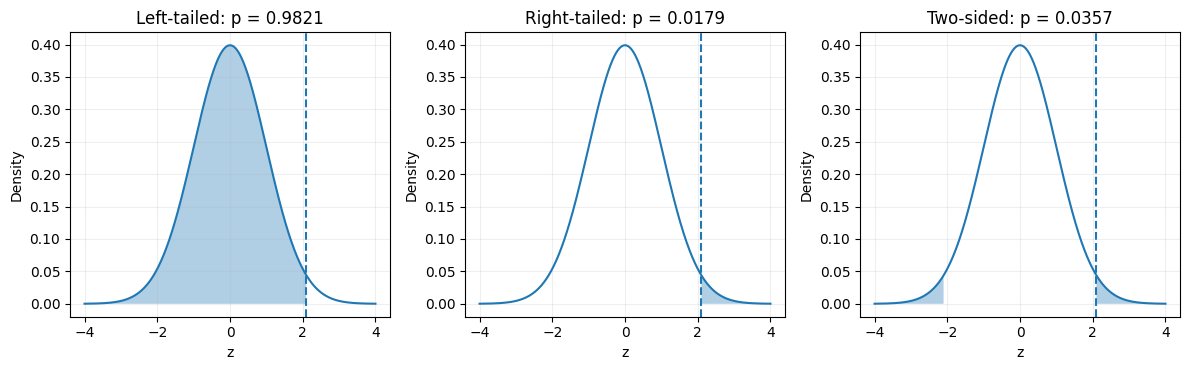

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

z_obs = 2.10
alpha = 0.05

p_values = {
    "Left-tailed": norm.cdf(z_obs),
    "Right-tailed": norm.sf(z_obs),
    "Two-sided": 2 * norm.sf(abs(z_obs))
}

for name, p_value in p_values.items():
    decision = "Reject H0" if p_value <= alpha else "Fail to reject H0"
    print(f"{name}: p={p_value:.5f} - {decision}")

x = np.linspace(-4, 4, 1000)
y = norm.pdf(x)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))

masks = [
    x <= z_obs,
    x >= z_obs,
    (x <= -abs(z_obs)) | (x >= abs(z_obs))
]

for ax, (name, p_value), mask in zip(axes, p_values.items(), masks):
    ax.plot(x, y)
    ax.fill_between(x, y, where=mask, alpha=0.35)
    ax.axvline(z_obs, linestyle="--")
    ax.set_title(f"{name}: p = {p_value:.4f}")
    ax.set_xlabel("z")
    ax.set_ylabel("Density")
    ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig("../../images/p_value_areas.png", dpi=180, bbox_inches="tight")
plt.show()

# Experiment: repeat with z_obs = -1.80.

## Experiment: p-values from other null distributions.

In [1]:
from scipy.stats import t, chi2, f

alpha = 0.05

# Two-sided Student's t-test, 9 degrees of freedom.
t_obs, t_df = 2.30, 9
t_p = 2 * t.sf(abs(t_obs), df=t_df)
t_cutoff = t.isf(alpha / 2, df=t_df)

# Right-tailed chi-square test, 4 degrees of freedom.
chi_obs, chi_df = 13.28, 4
chi_p = chi2.sf(chi_obs, df=chi_df)
chi_cutoff = chi2.isf(alpha, df=chi_df)

# Right-tailed F-test, degrees of freedom (5, 10).
f_obs, df_num, df_den = 3.50, 5, 10
f_p = f.sf(f_obs, dfn=df_num, dfd=df_den)
f_cutoff = f.isf(alpha, dfn=df_num, dfd=df_den)

print(f"t-test: p={t_p:.5f}, upper cutoff={t_cutoff:.4f}")
print(f"Chi-square: p={chi_p:.5f}, cutoff={chi_cutoff:.4f}")
print(f"F-test: p={f_p:.5f}, cutoff={f_cutoff:.4f}")

# Experiment: change the degrees of freedom and compare p-values.

t-test: p=0.04700, upper cutoff=2.2622
Chi-square: p=0.00999, cutoff=9.4877
F-test: p=0.04349, cutoff=3.3258


## Experiment: exact binomial p-values.

In [2]:
from scipy.stats import binom, binomtest

n = 10
p_0 = 0.5
alpha = 0.05

for successes in [8, 9]:
    right_p = binom.sf(successes - 1, n, p_0)
    exact_p = binomtest(
        successes, n, p_0, alternative="greater"
    ).pvalue

    print(f"Observed heads: {successes}")
    print(f"Right-tail p-value: {right_p:.5f}")
    print(f"Exact test p-value: {exact_p:.5f}")
    print("Reject:", exact_p <= alpha)
    print()

print(
    "Two-sided p-value for 8 heads:",
    binomtest(8, n, p_0, alternative="two-sided").pvalue
)

# Experiment: repeat for a null probability p_0 = 0.3.

Observed heads: 8
Right-tail p-value: 0.05469
Exact test p-value: 0.05469
Reject: False

Observed heads: 9
Right-tail p-value: 0.01074
Exact test p-value: 0.01074
Reject: True

Two-sided p-value for 8 heads: 0.109375


## Experiment: confidence interval and z-test decision.

In [3]:
from scipy.stats import norm

sample_mean = 54.5
mu_0 = 50.0
sigma = 10.0
n = 25
alpha = 0.05

standard_error = sigma / n**0.5
z_obs = (sample_mean - mu_0) / standard_error
p_value = 2 * norm.sf(abs(z_obs))

margin = norm.isf(alpha / 2) * standard_error
lower = sample_mean - margin
upper = sample_mean + margin

reject_by_p = p_value <= alpha
reject_by_ci = not (lower <= mu_0 <= upper)

print(f"Observed z: {z_obs:.2f}")
print(f"Two-sided p-value: {p_value:.5f}")
print(f"95% CI: ({lower:.2f}, {upper:.2f})")
print("Reject by p-value:", reject_by_p)
print("Reject by confidence interval:", reject_by_ci)

assert reject_by_p == reject_by_ci

# Experiment: repeat with sample_mean = 53.0.

Observed z: 2.25
Two-sided p-value: 0.02445
95% CI: (50.58, 58.42)
Reject by p-value: True
Reject by confidence interval: True


## Experiment: p-value calibration under a true null.

Normal rejection frequency: 0.04929
Binomial rejection frequency: 0.01065


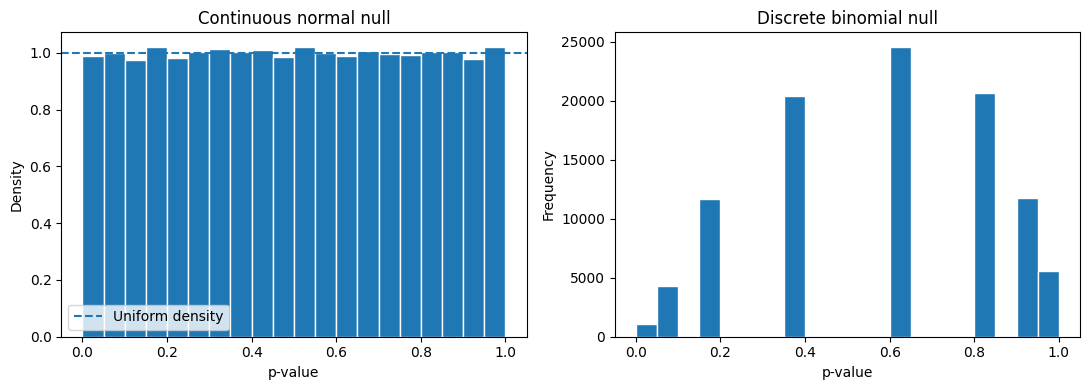

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, binom

rng = np.random.default_rng(2026)
repetitions = 100_000
alpha = 0.05

# Exactly calibrated continuous normal test.
z = rng.standard_normal(repetitions)
p_normal = 2 * norm.sf(np.abs(z))

# Conservative discrete right-tailed binomial test.
heads = rng.binomial(n=10, p=0.5, size=repetitions)
p_binomial = binom.sf(heads - 1, n=10, p=0.5)

print("Normal rejection frequency:", np.mean(p_normal <= alpha))
print("Binomial rejection frequency:", np.mean(p_binomial <= alpha))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(p_normal, bins=20, density=True, edgecolor="white")
axes[0].axhline(1, linestyle="--", label="Uniform density")
axes[0].set_title("Continuous normal null")
axes[0].set_xlabel("p-value")
axes[0].set_ylabel("Density")
axes[0].legend()

axes[1].hist(p_binomial, bins=20, range=(0, 1), edgecolor="white")
axes[1].set_title("Discrete binomial null")
axes[1].set_xlabel("p-value")
axes[1].set_ylabel("Frequency")

fig.tight_layout()
fig.savefig("../../images/pvalue_uniformity.png", dpi=180, bbox_inches="tight")
plt.show()

# Experiment: change alpha to 0.01 and 0.10.

## Experiment: one-sample t-test from data.

In [5]:
import pandas as pd
from scipy.stats import ttest_1samp

url = (
    "https://userpage.fu-berlin.de/"
    "soga/data/raw-data/students.csv"
)

students = pd.read_csv(url)
weights = students["weight"].dropna()

sample = weights.sample(n=30, random_state=17)
mu_0 = 70.8
alpha = 0.05

result = ttest_1samp(
    sample,
    popmean=mu_0,
    alternative="two-sided"
)

print("Sample size:", len(sample))
print("Sample mean:", round(sample.mean(), 2))
print("t-statistic:", round(result.statistic, 4))
print("p-value:", round(result.pvalue, 5))

if result.pvalue <= alpha:
    print("Reject H0 at the 5% level")
else:
    print("Fail to reject H0 at the 5% level")

# Experiment: change the benchmark or the alternative.
# The CSV must be accessible when this script is run.

Sample size: 30
Sample mean: 73.13
t-statistic: 1.7914
p-value: 0.08367
Fail to reject H0 at the 5% level
